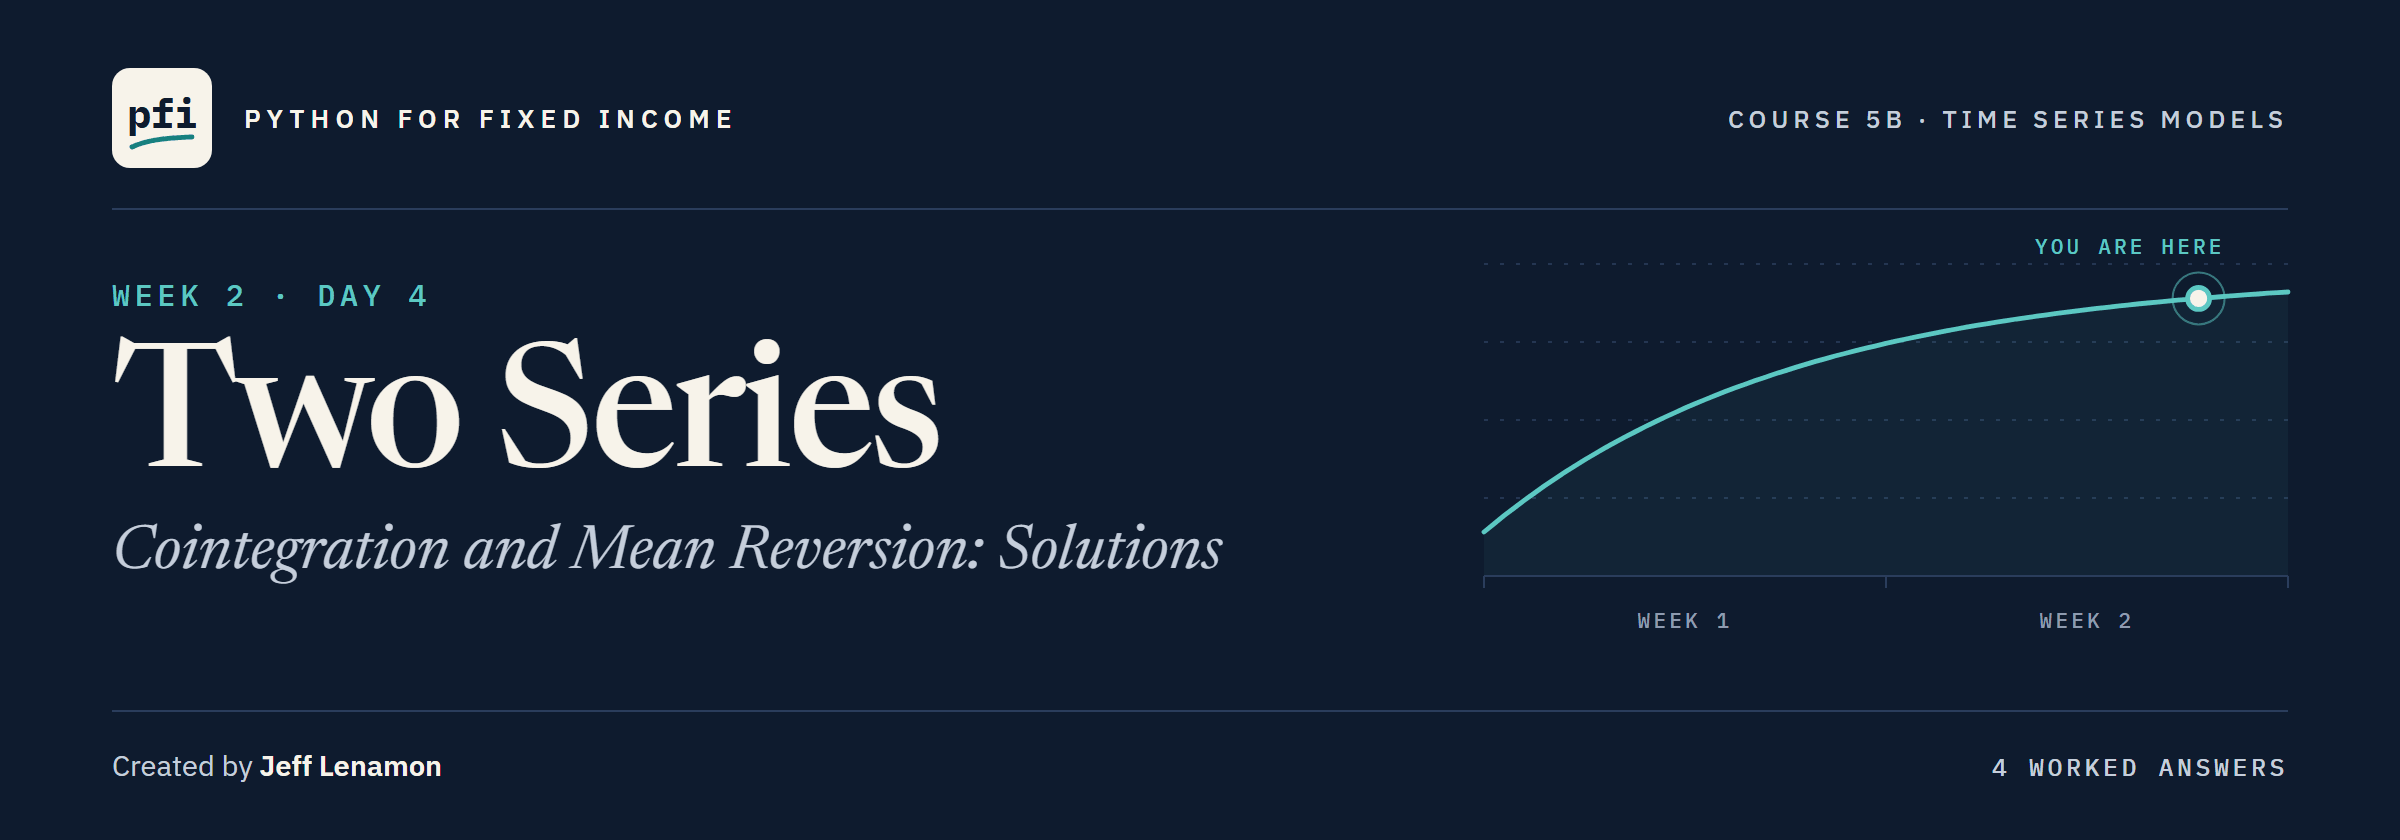

# Two Series: Cointegration and Mean Reversion: Solutions

Week 2, Day 4. The full notebook with every exercise worked. Try each one yourself first.

**Data:** `treasury_par_yields.csv`, 2,940 days of U.S. Treasury par yields, 2015-01-02 to 2026-10-02: **real**, U.S. Department of the Treasury, public domain.

**Data:** `course3_synthetic_spreads.csv`, 2,940 daily investment grade and high yield spreads in bp, one per date of the Treasury file: **synthetic**, invented for Course 3, not ICE, Moody's, or any index.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05b_time_series/week2/day4/09_two_series_cointegration_and_mean_reversion_solutions.ipynb)

# Problem Statement

## Business Context

Day 3 found that two wandering series nearly always find a line between them, and promised a test for a link that survives.
A desk follows pairs of series: the 10 Yr against the 5 Yr, both real, and the HY spread against the IG spread, both synthetic.
The 2s10s slope is already a gap between two series with the ratio fixed at 1, and Day 3 found that it wanders.
Today the data picks the ratio, a test says whether the gap holds a level, and a half-life says how fast it closed.
Every number here describes 2015 to 2022, and none of it is a trade, an entry, or a view on rates or spreads.

## Objectives

Compare a pair's correlation in levels and in changes, fit a hedge ratio by eye and by least squares, build the gap, and map where a pair moved from each place it stood.
Run the Engle-Granger test with `coint` and read its statistic and p-value, measure a half-life from an AR(1) on the gap and check its sign, and follow the hedge ratio through the years and onto later dates.

## Data Dictionary

`treasury_par_yields.csv` and `course3_synthetic_spreads.csv`, one row per trading day:

1. `date`: the trading day
2. `5 Yr`, `10 Yr`: par yields, in percent (the other 12 tenors are not used)
3. `ig_spread_bp`, `hy_spread_bp`: the synthetic IG and HY spreads, in bp

Made here: the four series `5 Yr`, `10 Yr`, `IG` and `HY` in bp, as levels and daily changes.
For each pair, the hedge ratio (bp of one series per bp of the other), the gap in bp, and the gap's half-life in trading days.

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# to draw charts, and a slider
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact

# Course 4's regression, Day 3's ADF test, and today's Engle-Granger test
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, coint

# Day 2's walk-forward folds
from sklearn.model_selection import TimeSeriesSplit

# one look for every chart, and four decimals in every table
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.float_format", "{:.4f}".format)

# Loading the Data

## Reading the Two Files and the Development Years

In [3]:
# the Treasury par yields (percent) and the synthetic spreads (bp), one row per trading day
yields = pd.read_csv(DATA + "treasury_par_yields.csv", parse_dates=["date"], index_col="date")
spreads = pd.read_csv(DATA + "course3_synthetic_spreads.csv", parse_dates=["date"], index_col="date")

# Day 2's cut: everything here sits in the development years; the held-out years stay closed
CUT = "2022-12-30"
development = yields.loc[:CUT]

## Four Series in bp

Day 2's series, with the 5 Yr made the same way for today's real pair.

In [4]:
# the four series in bp: yields times 100, rounded to two places to drop the binary tail (Course 3)
levels = pd.DataFrame({"5 Yr": (development["5 Yr"] * 100).round(2),
                       "10 Yr": (development["10 Yr"] * 100).round(2),
                       "IG": spreads.loc[:CUT, "ig_spread_bp"],
                       "HY": spreads.loc[:CUT, "hy_spread_bp"]})

# each series' daily change in bp: the level less the level one row before
changes = levels.diff().dropna()
print(levels.shape, changes.shape, levels.index[0].date(), "to", levels.index[-1].date())

(2001, 4) (2000, 4) 2015-01-02 to 2022-12-30


## Day 2's Folds

In [5]:
# Day 2's five folds, here on the 2,001 levels: row positions for training, then for testing
folds = list(TimeSeriesSplit(n_splits=5, test_size=252).split(levels))
for k, (train, test) in enumerate(folds, start=1):
    print(f"fold {k}: {len(train)} training levels to {levels.index[train[-1]].date()} | test {levels.index[test[0]].date()} to {levels.index[test[-1]].date()}")

fold 1: 741 training levels to 2017-12-14 | test 2017-12-15 to 2018-12-19
fold 2: 993 training levels to 2018-12-19 | test 2018-12-20 to 2019-12-23
fold 3: 1245 training levels to 2019-12-23 | test 2019-12-24 to 2020-12-24
fold 4: 1497 training levels to 2020-12-24 | test 2020-12-28 to 2021-12-28
fold 5: 1749 training levels to 2021-12-28 | test 2021-12-29 to 2022-12-30


The same 1,260 test dates as Day 2; on levels, each training window holds one more row.

The folds wait for the last section.

**Four series in bp on the development years, and Day 2's folds set aside for later.**

# Data Overview

## Checking the Statistical Summary

In [6]:
levels.describe()

,5 Yr,10 Yr,IG,HY
count,2001.0000,2001.0000,2001.0000,2001.0000
mean,173.1474,207.8826,87.1356,240.5106
std,88.7875,73.8736,8.9974,33.1905
min,19.0000,52.0000,64.7000,157.5000
25%,118.0000,160.0000,81.3000,215.6000
50%,165.0000,212.0000,86.4000,240.4000
75%,233.0000,254.0000,91.8000,262.1000
max,445.0000,425.0000,125.9000,359.1000


The 5 Yr ran from 19 to 445 bp, the 10 Yr from 52 to 425.

IG stayed between 64.7 and 125.9 bp, HY between 157.5 and 359.1.

## Each Level Alone

Day 3's ADF test, a unit root as its null hypothesis, on each level.

In [7]:
# ADF's p-value on each level, with Day 3's default lag search
pd.Series({name: adfuller(levels[name].to_numpy(), result_object=True).pvalue for name in levels}, name="ADF p-value")

5 Yr    0.9620
10 Yr   0.8699
IG      0.5529
HY      0.0793
Name: ADF p-value, dtype: float64

Every p-value is above 0.05: no level is cleared of a unit root, the 5 Yr included.

**Each level wanders on its own. Today asks whether two of them wander together.**

# Exploratory Data Analysis

## Two Pairs Over Eight Years

`ax.twinx()` (Course 5) gives the IG spread its own axis on the right, since HY sits far above it.

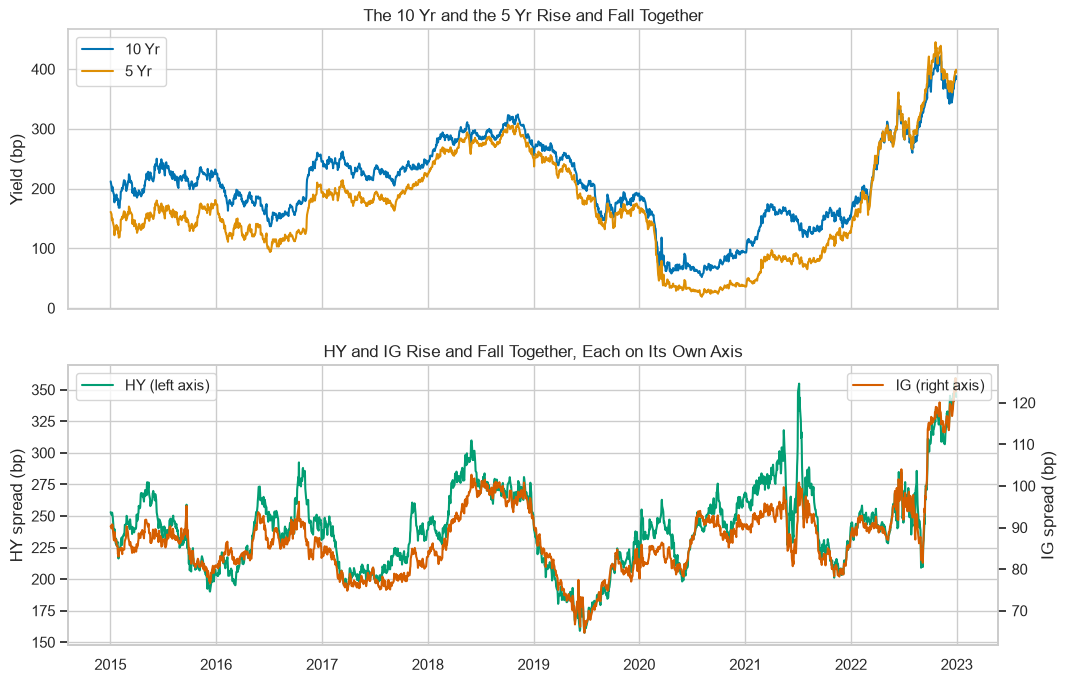

In [8]:
# each pair over the development years: the Treasuries on one axis, HY on the left and IG on the right
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
axes[0].plot(levels["10 Yr"], label="10 Yr")
axes[0].plot(levels["5 Yr"], label="5 Yr")
axes[0].set(ylabel="Yield (bp)", title="The 10 Yr and the 5 Yr Rise and Fall Together")
axes[0].legend(loc="upper left")
axes[1].plot(levels["HY"], color="C2", label="HY (left axis)")
right = axes[1].twinx()
right.plot(levels["IG"], color="C3", label="IG (right axis)")
right.grid(False)
axes[1].set(ylabel="HY spread (bp)", title="HY and IG Rise and Fall Together, Each on Its Own Axis")
right.set_ylabel("IG spread (bp)")
axes[1].legend(loc="upper left")
right.legend(loc="upper right")
plt.show()

Each pair climbs and falls in step: the yields through the 2020 low and the 2022 climb, the spreads through the 2019 low and the 2022 high.

Day 3 showed what two wandering series can do together by luck.

## Each Pair as a Scatter

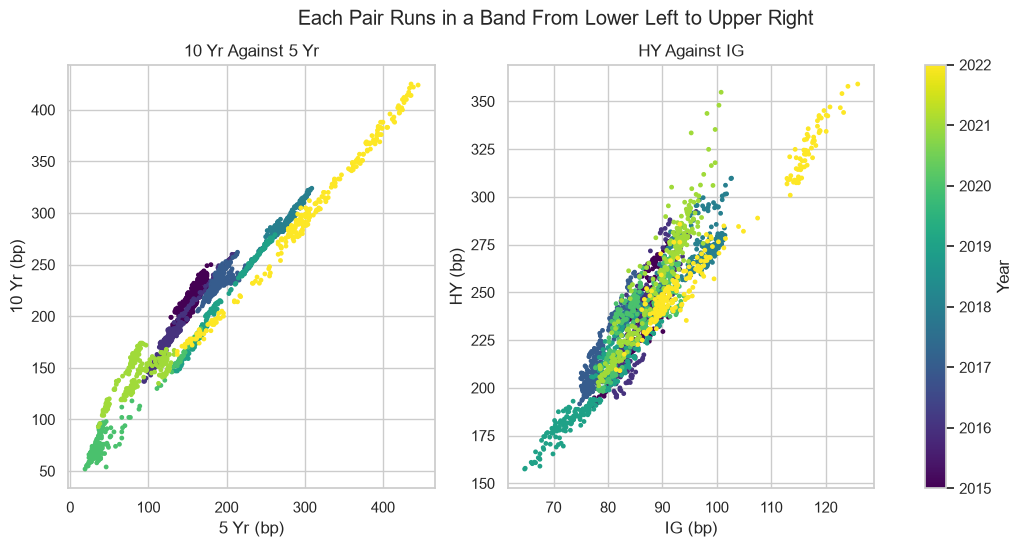

In [9]:
# one series against the other, each date a dot coloured by its year (Course 4's Day 11)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (y_name, x_name) in zip(axes, [("10 Yr", "5 Yr"), ("HY", "IG")]):
    dots = ax.scatter(levels[x_name], levels[y_name], c=levels.index.year, cmap="viridis", s=6)
    ax.set(xlabel=x_name + " (bp)", ylabel=y_name + " (bp)", title=f"{y_name} Against {x_name}")
fig.colorbar(dots, ax=axes, label="Year")
fig.suptitle("Each Pair Runs in a Band From Lower Left to Upper Right")
plt.show()

Both clouds run in a band from lower left to upper right.

On the Treasuries each year holds its own stretch of the band, often on a line of its own beside the next year's.

On HY and IG the years overlap, apart from the widest spreads of late 2022 at the top right.

## Correlation in Levels and in Changes

Q. Do the two pairs look alike to a correlation?

In [10]:
# each pair's correlation in levels and in daily changes
pairs = {"10 Yr on 5 Yr": ("10 Yr", "5 Yr"), "HY on IG": ("HY", "IG")}
pd.DataFrame({"levels": [levels[y].corr(levels[x]) for y, x in pairs.values()],
              "changes": [changes[y].corr(changes[x]) for y, x in pairs.values()]}, index=list(pairs))

,levels,changes
10 Yr on 5 Yr,0.9741,0.9316
HY on IG,0.9222,0.8590


Above 0.9 in levels for both pairs, and above 0.8 in changes.

Day 3's spurious regression showed that a correlation of two wandering levels can mean nothing.

**Correlation cannot tell these two pairs apart. The gap between the two series can.**

# The Hedge Ratio and the Gap

![A pair drawn as one series y against another x, with a straight line through the cloud: y equals a constant plus the hedge ratio times x. The gap on a date is how far y sits above or below that line, in bp. The 2s10s slope is the same gap with a ratio of 1 and a constant of 0](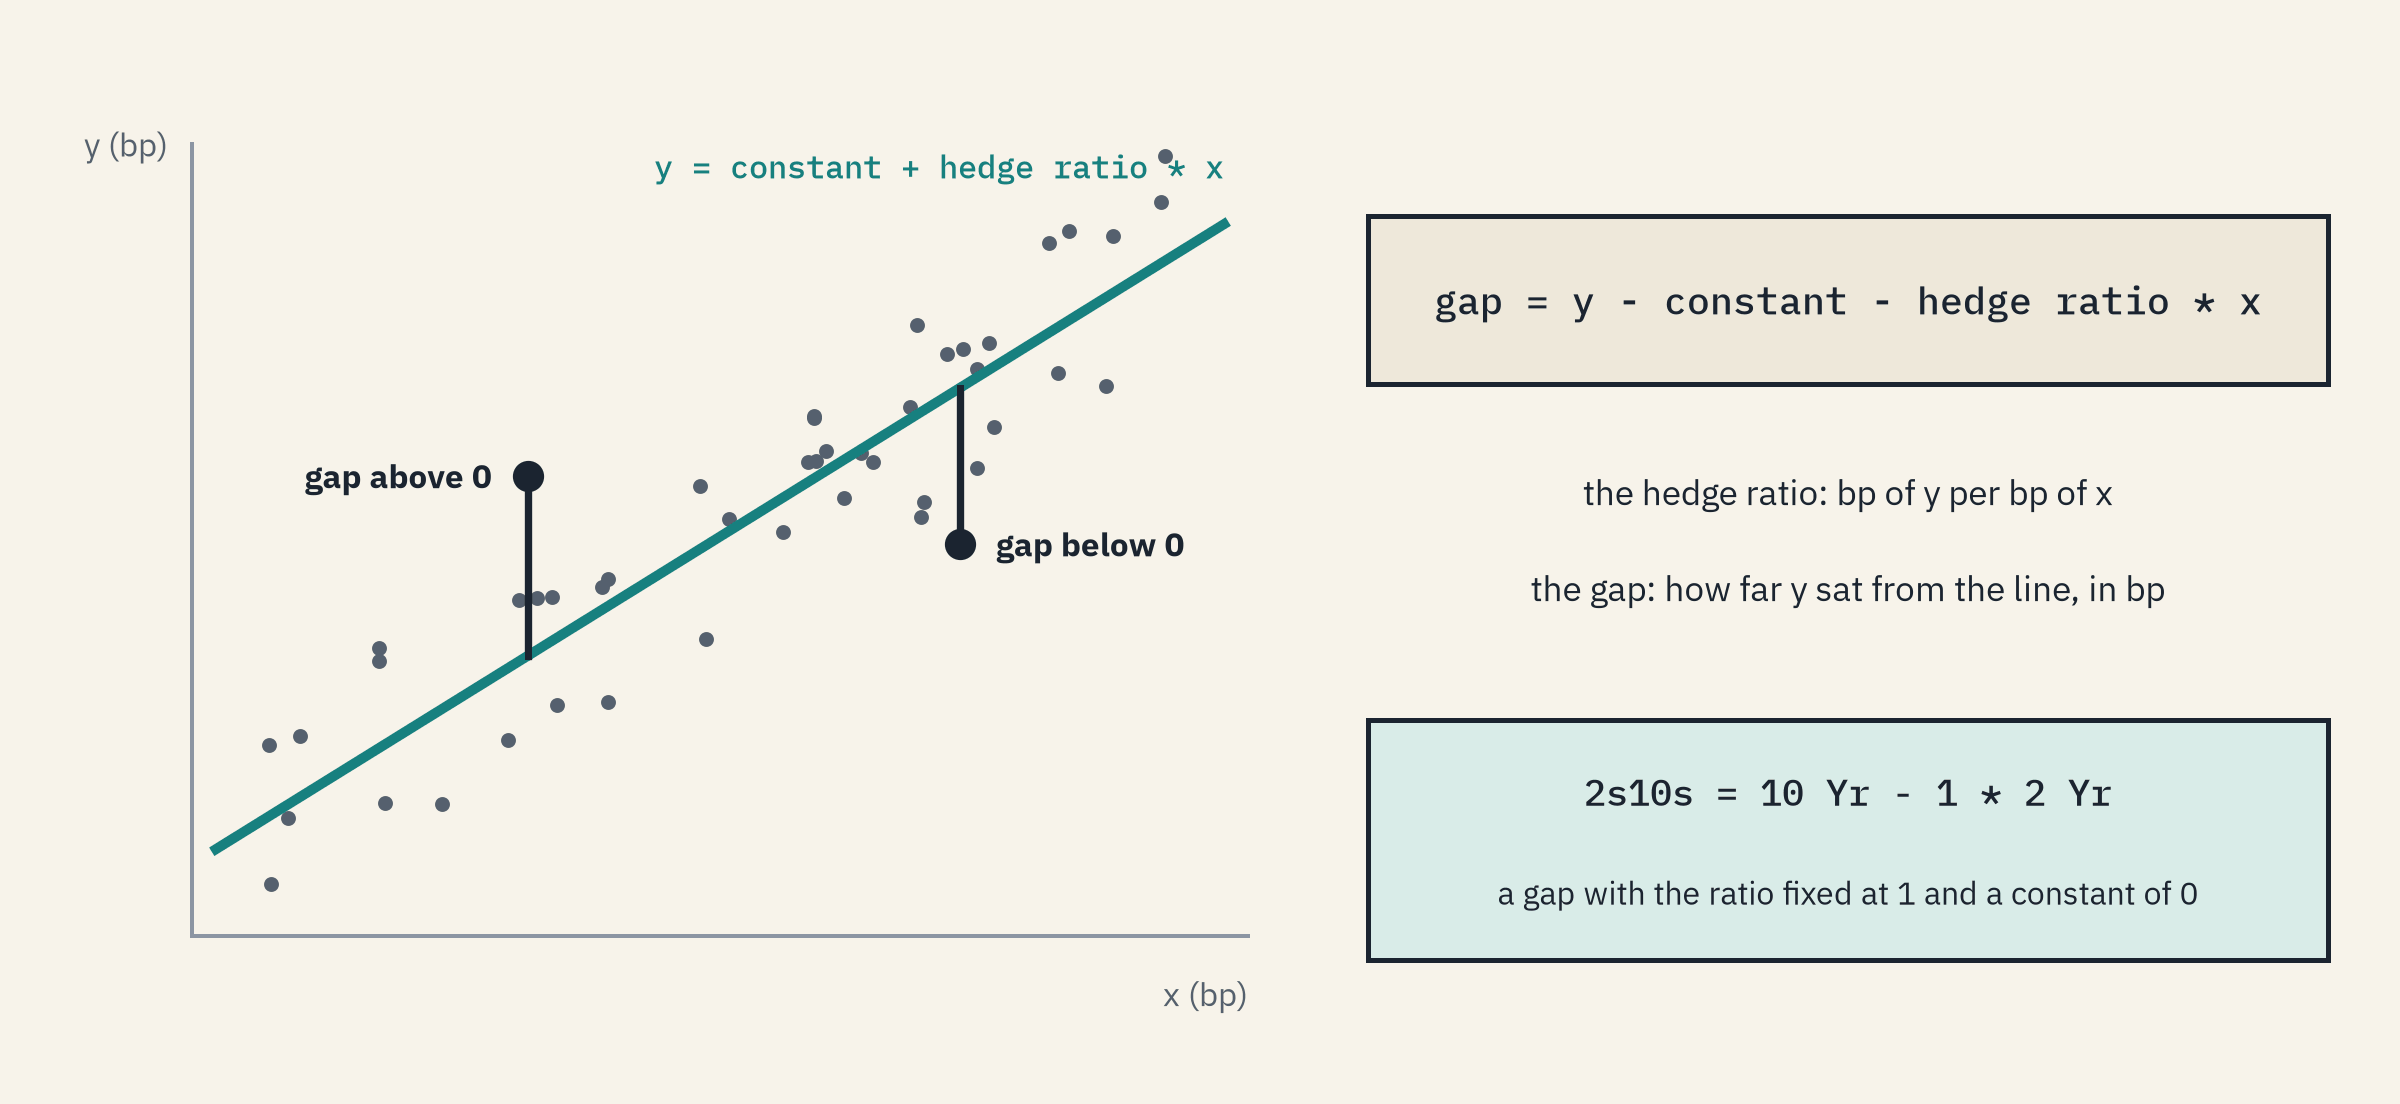)

A **pair** is two series followed together, one written y and the other x.
The **hedge ratio** is the bp y moved per bp of x, a number fitted on this file's dates, and the **gap** is y less a constant less the ratio times x, in bp.
The 2s10s slope is this gap with a ratio of 1 and a constant of 0.

**Predict 1**

Q. Which hedge ratio of HY on IG gives the gap its smallest standard deviation? Write down a number.

## Your Turn: Find the Ratio by Eye

In [11]:
# the gap of HY on IG at any ratio, less its own mean, and its standard deviation at every ratio from 0 to 6
def hy_gap(ratio):
    gap = levels["HY"] - ratio * levels["IG"]
    return gap - gap.mean()

ratios = np.round(np.arange(0, 6.01, 0.1), 1)
gap_std = pd.Series([hy_gap(r).std() for r in ratios], index=ratios)

In [12]:
# your turn: move the ratio and watch the gap and its standard deviation
def draw_gap(ratio=2.0):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), width_ratios=[3, 2])
    axes[0].plot(hy_gap(ratio), linewidth=0.8)
    axes[0].set(ylabel="Gap less its mean (bp)", title=f"HY Less {ratio:.1f} x IG")
    axes[1].plot(gap_std.index, gap_std, color="gray")
    axes[1].scatter([ratio], [hy_gap(ratio).std()], s=90, color="C1", zorder=3)
    axes[1].set(xlabel="Hedge ratio", ylabel="Std of the gap (bp)", title=f"Std {hy_gap(ratio).std():.2f} bp at {ratio:.1f}")
    plt.show()

interact(draw_gap, ratio=(0.0, 6.0, 0.1));

interactive(children=(FloatSlider(value=2.0, description='ratio', max=6.0), Output()), _dom_classes=('widget-i…

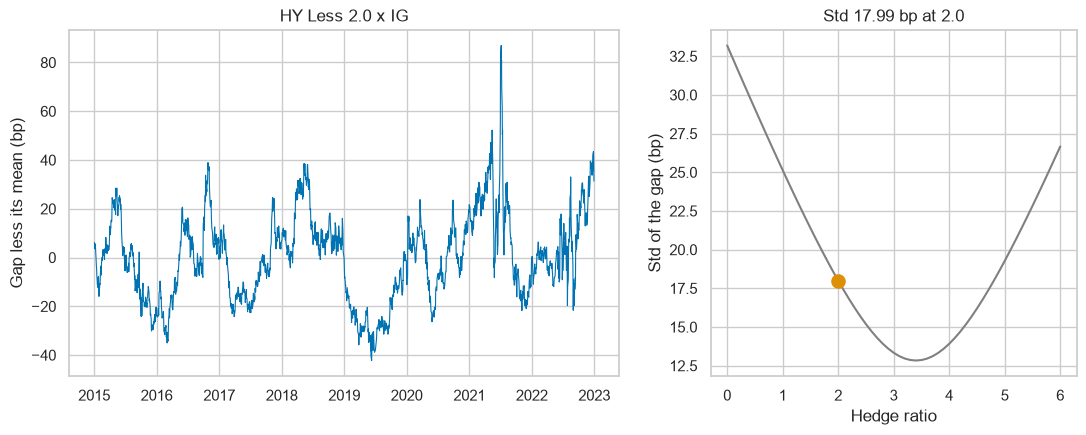

In [13]:
# the slider's starting position, drawn as a still picture (sliders do not run on GitHub)
draw_gap(2.0)

In [14]:
# the gap's standard deviation at three ratios, in bp
gap_std[[0.0, 3.0, 4.0]]

0.0000   33.1905
3.0000   13.3329
4.0000   13.9151
dtype: float64

At a ratio of 0 the gap is HY itself, with a standard deviation of 33.19 bp.

The curve falls to a floor between 3 and 4 and climbs again.

## The Machine's Ratio

Course 4's least squares finds that floor: y on a constant and x, fitted on values without their dates.

In [15]:
# each pair's line by least squares: the constant in bp, the hedge ratio, and the gap left on each date
gaps = {}
for label, (y_name, x_name) in pairs.items():
    fit = sm.OLS(levels[y_name].to_numpy(), sm.add_constant(levels[x_name].to_numpy())).fit()
    constant, ratio = fit.params
    gaps[label] = levels[y_name] - constant - ratio * levels[x_name]
    print(f"{label}: constant {constant:.2f} bp, hedge ratio {ratio:.3f}, gap std {gaps[label].std():.3f} bp")

10 Yr on 5 Yr: constant 67.56 bp, hedge ratio 0.810, gap std 16.716 bp
HY on IG: constant -55.93 bp, hedge ratio 3.402, gap std 12.833 bp


### Interpretation of the Hedge Ratio

Over these years HY moved 3.40 bp per bp of IG, and the 10 Yr 0.81 bp per bp of the 5 Yr.

Least squares makes the sum of squared gaps as small as it can be, so it lands on the slider's floor.

In [16]:
# the same lines fitted on daily changes in bp
for label, (y_name, x_name) in pairs.items():
    ratio = sm.OLS(changes[y_name].to_numpy(), sm.add_constant(changes[x_name].to_numpy())).fit().params[1]
    print(f"{label}: hedge ratio on changes {ratio:.3f}")

10 Yr on 5 Yr: hedge ratio on changes 0.944
HY on IG: hedge ratio on changes 3.619


On changes the ratios are 0.944 and 3.619: a ratio belongs to what it was fitted on.

## The Gap With Bands of Its Own Spread

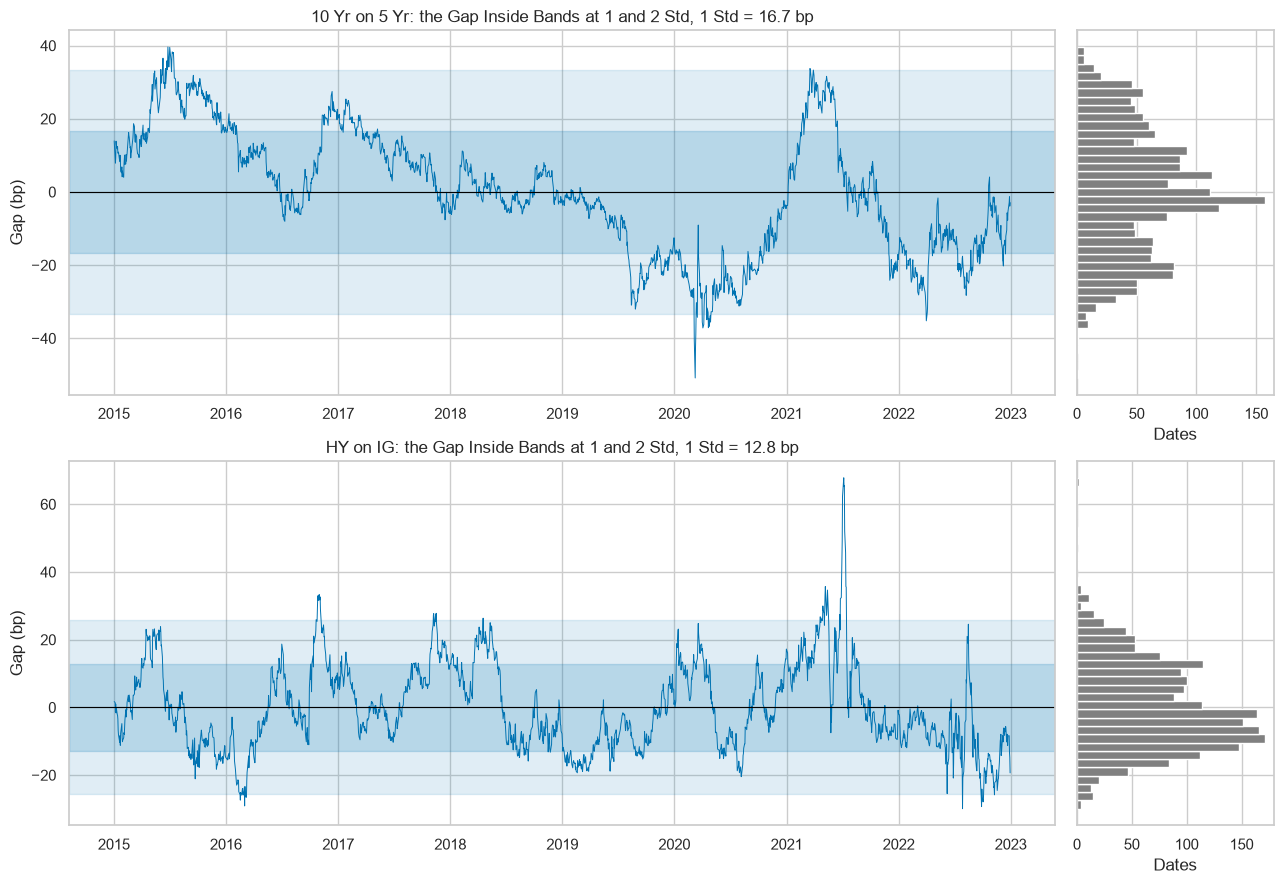

In [17]:
# each gap over the years with bands at 1 and 2 standard deviations, and its histogram on its side
fig, axes = plt.subplots(2, 2, figsize=(13, 9), width_ratios=[5, 1], sharey="row")
for row, (label, gap) in enumerate(gaps.items()):
    std = gap.std()
    axes[row, 0].plot(gap, linewidth=0.7)
    for k, shade in [(2, 0.12), (1, 0.18)]:
        axes[row, 0].axhspan(-k * std, k * std, color="C0", alpha=shade)
    axes[row, 0].axhline(0, color="black", linewidth=0.8)
    axes[row, 0].set(ylabel="Gap (bp)", title=f"{label}: the Gap Inside Bands at 1 and 2 Std, 1 Std = {std:.1f} bp")
    axes[row, 1].hist(gap, bins=40, orientation="horizontal", color="gray")
    axes[row, 1].set(xlabel="Dates")
plt.tight_layout()
plt.show()

Day 5's marginal histogram on the right counts the gap's dates along the same axis.

In [18]:
# for each gap: dates beyond 2 std, times it crossed zero, and the longest run of dates on one side of zero
for label, gap in gaps.items():
    side = np.sign(gap)
    runs = side.groupby((side != side.shift()).cumsum()).size()
    beyond = (gap.abs() > 2 * gap.std()).sum()
    print(f"{label}: beyond 2 std on {beyond} dates ({beyond / len(gap):.1%}), crossed zero {len(runs) - 1} times, longest run {runs.max()} dates")

10 Yr on 5 Yr: beyond 2 std on 39 dates (1.9%), crossed zero 69 times, longest run 462 dates
HY on IG: beyond 2 std on 60 dates (3.0%), crossed zero 87 times, longest run 222 dates


The Treasury gap spent 462 dates in a row on one side of zero, nearly two years; the HY gap's longest run was 222.

The HY gap crossed zero 87 times, the Treasury gap 69.

The bands measure how big the gap was in its own units over these years, nothing to act on.

**Both gaps average zero by construction. Whether a gap keeps coming back to zero is the question.**

# The Pair's Moves on a Map

## Twenty Trading Days From Every Spot

A **vector field** draws an arrow at each spot of a map: here, the average move a pair made from that spot.
The map lays the least-squares line flat: x across, the gap up, so the line is the gap's zero.
For each date: where x and the gap stood 20 rows before (`shift(20)`, past only), and the 20-row move since, in bp.

In [19]:
# for one pair: where x and the gap stood 20 rows before each date, and the move in bp from there to the date
def moves(label, x_name):
    x, gap = levels[x_name], gaps[label]
    table = pd.DataFrame({"x": x.shift(20), "gap": gap.shift(20), "dx": x - x.shift(20), "dgap": gap - gap.shift(20)}).dropna()
    # Course 1's pd.cut on both axes makes a grid of cells; each cell keeps its average spot, its average move and its dates
    cells = table.groupby([pd.cut(table["x"], 8), pd.cut(table["gap"], 8)], observed=True)
    cells = cells.agg(x=("x", "mean"), gap=("gap", "mean"), dx=("dx", "mean"), dgap=("dgap", "mean"), dates=("x", "size"))
    return table, cells[cells["dates"] >= 15]

field = {label: moves(label, x_name) for label, (y_name, x_name) in pairs.items()}

`ax.quiver(x, y, dx, dy, angles="xy", scale_units="xy", scale=1)` draws one arrow per cell from (x, y), its length in the chart's own bp.

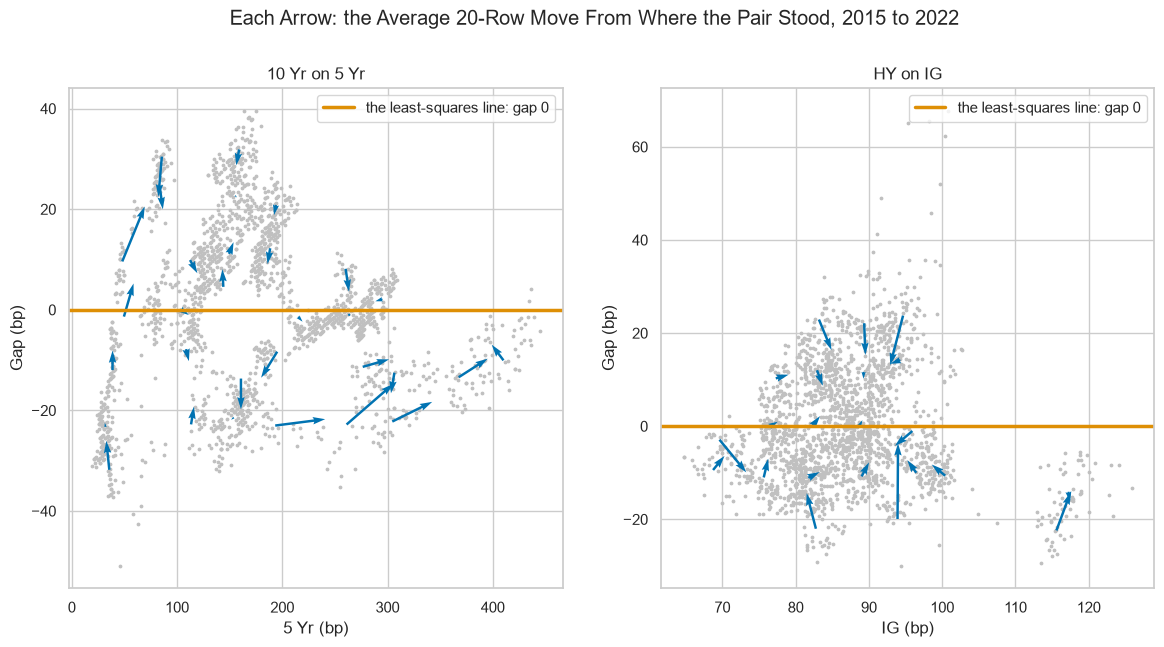

In [20]:
# the showpiece: each cell's average 20-row move as an arrow, over every date's spot, with the gap's zero line
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
for ax, (label, (y_name, x_name)) in zip(axes, pairs.items()):
    table, cells = field[label]
    ax.scatter(levels[x_name], gaps[label], s=3, color="silver")
    ax.axhline(0, color="C1", linewidth=2.5, label="the least-squares line: gap 0")
    ax.quiver(cells["x"], cells["gap"], cells["dx"], cells["dgap"], angles="xy", scale_units="xy", scale=1, color="C0", width=0.005)
    ax.set(xlabel=x_name + " (bp)", ylabel="Gap (bp)", title=label)
    ax.legend(loc="upper right")
fig.suptitle("Each Arrow: the Average 20-Row Move From Where the Pair Stood, 2015 to 2022", y=1.0)
plt.show()

In [21]:
# for each cell: did the gap move toward zero? Then the gap against its 20-row move, by cell and by date
for label in pairs:
    table, cells = field[label]
    toward = (np.sign(cells["gap"]) != np.sign(cells["dgap"])).sum()
    print(f"{label}: {toward} of {len(cells)} cells moved toward 0 | correlation of the gap and its move: "
          f"cells {cells['gap'].corr(cells['dgap']):.2f}, dates {table['gap'].corr(table['dgap']):.2f}")

10 Yr on 5 Yr: 21 of 31 cells moved toward 0 | correlation of the gap and its move: cells -0.42, dates -0.20
HY on IG: 16 of 22 cells moved toward 0 | correlation of the gap and its move: cells -0.78, dates -0.42


HY on IG: 16 of 22 cells moved toward zero, the arrows above the line pointing down and those below it up.

The cells' correlation of the gap with its 20-row move is -0.78; date by date it is -0.42.

10 Yr on 5 Yr: 21 of 31 cells, with correlations of -0.42 and -0.20, and many arrows run sideways along the 5 Yr.

**One pair leaned back to its line, the other slid along it. A test turns the picture into a number.**

# Testing the Gap: Engle-Granger

Two series are **cointegrated** when each wanders but a mix of them, the gap, holds a level.
The **Engle-Granger test** takes two steps: fit the line by least squares, then test the gap for a unit root.

**Predict 2**

Day 3's ADF clears a single random walk of its unit root about 5 times in 100, as a test at 5 percent should.

Q. Draw 1,000 pairs of independent random walks, fit each pair's line by least squares, and run Day 3's ADF on each fitted gap. How many gaps will it clear of a unit root at 5 percent? Write down a number.

## Day 3's ADF on a Fitted Gap

In [22]:
# 1,000 pairs of independent random walks of 500 rows each, from the course's seeded generator
rng = np.random.default_rng(SEED)
walk_pairs = rng.standard_normal((1000, 2, 500)).cumsum(axis=2)

# each pair's line by Course 1's polyfit, then Day 3's ADF on the gap, and on the walk y alone
# maxlag=0 and autolag=None: no lag search (Day 3's plain form), so 2,000 tests take about a second
gap_tests, walk_tests = [], []
for y, x in walk_pairs:
    ratio, constant = np.polyfit(x, y, 1)
    gap_tests.append(adfuller(y - constant - ratio * x, maxlag=0, autolag=None, result_object=True))
    walk_tests.append(adfuller(y, maxlag=0, autolag=None, result_object=True))

In [23]:
# how many each test clears at 5 percent, and the statistic that 5 percent of the gaps fall below
gap_stats = np.array([test.statistic for test in gap_tests])
walk_stats = np.array([test.statistic for test in walk_tests])
print("fitted gaps cleared:", sum(test.pvalue < 0.05 for test in gap_tests), "of 1,000")
print("single walks cleared:", sum(test.pvalue < 0.05 for test in walk_tests), "of 1,000")
print(f"5 percent points: ADF's table {walk_tests[0].critical_values['5%']:.2f}, the fitted gaps {np.quantile(gap_stats, 0.05):.2f}")

fitted gaps cleared: 165 of 1,000
single walks cleared: 54 of 1,000
5 percent points: ADF's table -2.87, the fitted gaps -3.36


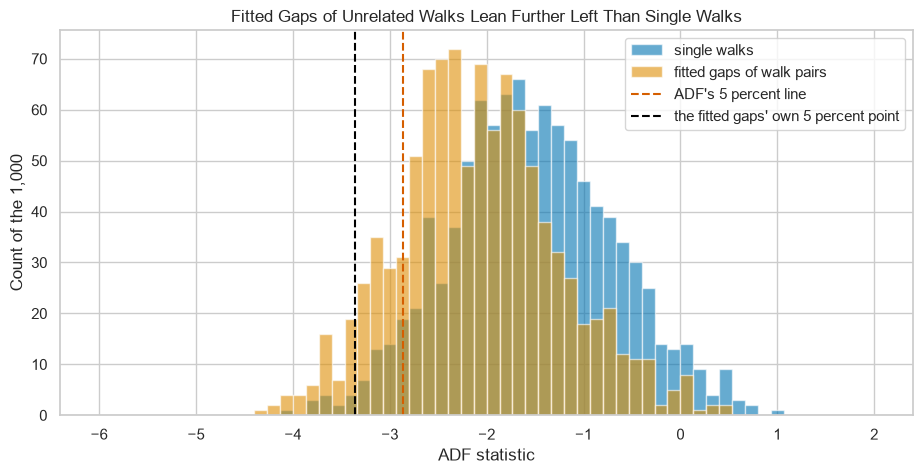

In [24]:
# the two piles of statistics, with ADF's 5 percent line and the fitted gaps' own 5 percent point
fig, ax = plt.subplots(figsize=(11, 5))
bins = np.linspace(-6, 2, 61)
ax.hist(walk_stats, bins=bins, alpha=0.6, label="single walks")
ax.hist(gap_stats, bins=bins, alpha=0.6, label="fitted gaps of walk pairs")
ax.axvline(walk_tests[0].critical_values["5%"], color="C3", linestyle="--", label="ADF's 5 percent line")
ax.axvline(np.quantile(gap_stats, 0.05), color="black", linestyle="--", label="the fitted gaps' own 5 percent point")
ax.set(xlabel="ADF statistic", ylabel="Count of the 1,000", title="Fitted Gaps of Unrelated Walks Lean Further Left Than Single Walks")
ax.legend(loc="upper right")
plt.show()

### Interpretation of the Two Piles

Least squares picks the ratio that makes the gap as small as it can, so a gap of two unrelated walks looks tighter than either walk.

Read against Day 3's table, 165 of 1,000 gaps of unrelated walks are cleared of a unit root, three times the 54 of single walks.

The fitted gaps' own 5 percent point is -3.36, against ADF's -2.87 for 500 rows.

A fitted gap needs a table of its own, built on fitted gaps.

## The Test With Its Own Table

![The Engle-Granger test in two steps. Step 1: fit y on a constant and x by least squares, and keep the gap, y less the constant less the hedge ratio times x. Step 2: test the gap for a unit root with an ADF regression, and read its statistic against the Engle-Granger table, not against the plain ADF table of Day 3, because the line in step 1 was chosen to make the gap as small as it can be](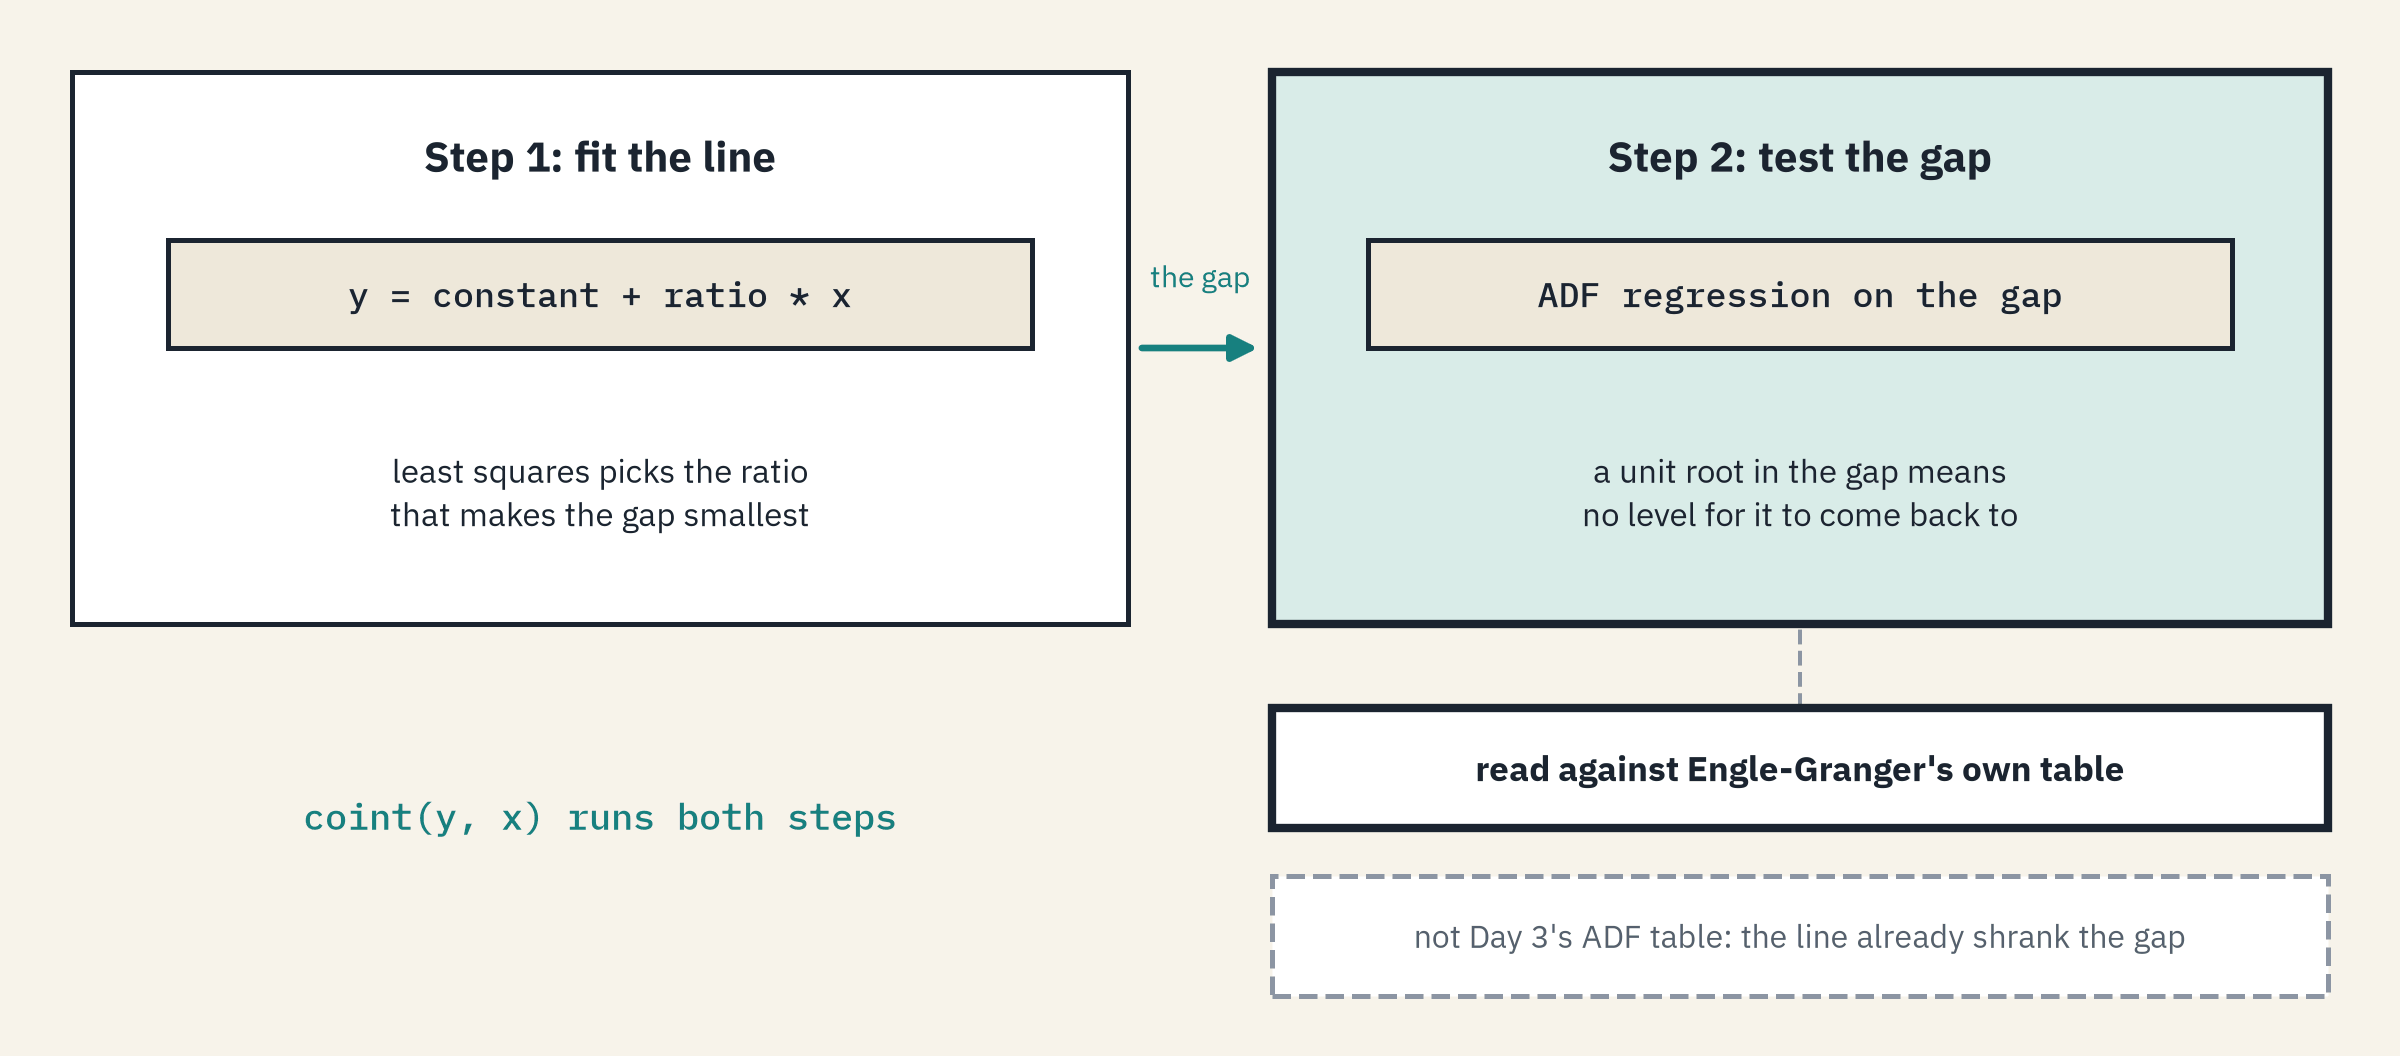)

`coint(y, x, trend="c", autolag="aic")` runs both steps and reads the statistic against Engle-Granger's own critical values, from MacKinnon's tables.
`trend="c"` fits the line with a constant, and `autolag="aic"` picks ADF's lags as Day 3's default did; it returns the statistic, the p-value, and the 1, 5 and 10 percent critical values.

In [25]:
# Engle-Granger on each pair, and Day 3's ADF, read against its own table, on the same least-squares gap
eg = {}
for label, (y_name, x_name) in pairs.items():
    eg[label] = coint(levels[y_name].to_numpy(), levels[x_name].to_numpy(), trend="c", autolag="aic")
    adf_p = adfuller(gaps[label].to_numpy(), result_object=True).pvalue
    print(f"{label}: statistic {eg[label][0]:.3f}, p-value {eg[label][1]:.4f} | Day 3's ADF on the gap: p-value {adf_p:.4f}")
print("Engle-Granger critical values (1, 5, 10 percent):", eg["HY on IG"][2].round(2))

10 Yr on 5 Yr: statistic -2.193, p-value 0.4281 | Day 3's ADF on the gap: p-value 0.2091
HY on IG: statistic -4.235, p-value 0.0032 | Day 3's ADF on the gap: p-value 0.0006
Engle-Granger critical values (1, 5, 10 percent): [-3.9  -3.34 -3.05]


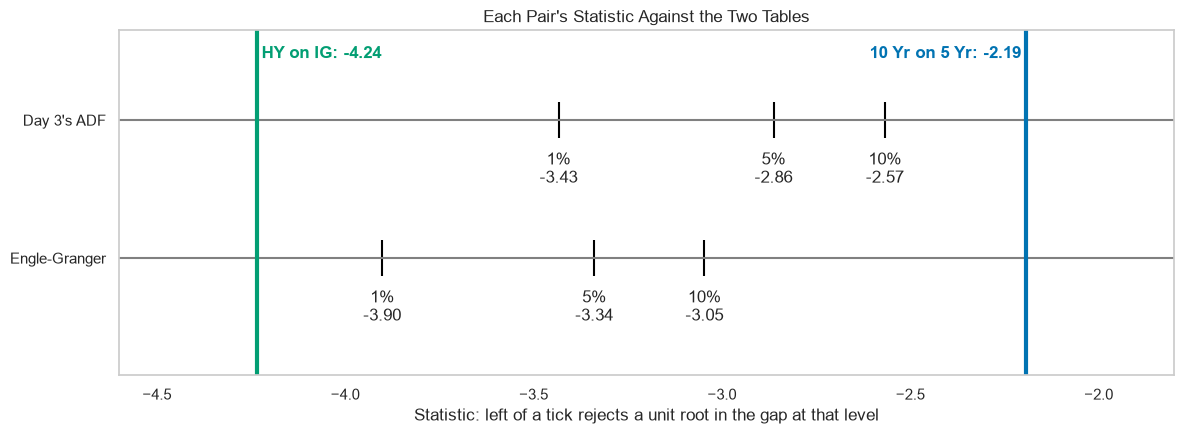

In [26]:
# two number lines: Day 3's ADF critical values and Engle-Granger's as ticks, each pair's statistic as a line across both
adf_lines = list(adfuller(levels["HY"].to_numpy(), result_object=True).critical_values.values())
fig, ax = plt.subplots(figsize=(12, 4.5))
for height, values in [(1, adf_lines), (0, eg["HY on IG"][2])]:
    ax.hlines(height, -4.6, -1.8, color="gray")
    ax.scatter(values, [height] * 3, marker="|", s=700, color="black")
    for value, level in zip(values, ["1%", "5%", "10%"]):
        ax.annotate(f"{level}\n{value:.2f}", (value, height), xytext=(0, -45), textcoords="offset points", ha="center")
# each pair's label sits beside its line: the 10 Yr's to the left, HY's to the right
for label, colour, side in [("10 Yr on 5 Yr", "C0", "right"), ("HY on IG", "C2", "left")]:
    ax.axvline(eg[label][0], color=colour, linewidth=3)
    ax.annotate(f" {label}: {eg[label][0]:.2f} ", (eg[label][0], 1.45), ha=side, color=colour, weight="bold")
ax.set(xlim=(-4.6, -1.8), ylim=(-0.85, 1.65), yticks=[0, 1], yticklabels=["Engle-Granger", "Day 3's ADF"])
ax.set(xlabel="Statistic: left of a tick rejects a unit root in the gap at that level", title="Each Pair's Statistic Against the Two Tables")
ax.grid(False)
plt.tight_layout()
plt.show()

### Interpretation of the Engle-Granger Test

HY on IG: a p-value of 0.0032 rejects "no cointegration" at 1 percent, with a statistic of -4.24, left of every tick.

10 Yr on 5 Yr: 0.43, no evidence over these years of a gap that holds a level, from two series correlated 0.97.

Day 3's ADF on the same gaps gives 0.0006 and 0.21, both too small, since its table expects a series no line was fitted to.

Engle-Granger's 5 percent value, -3.34, sits close to the -3.36 the 1,000 walk pairs gave.

Course 3's generator built each day's shock to the synthetic HY spread's log level as 1.3 times IG's shock plus noise of its own, so the test found a tie that was put into the file.

It says nothing about real HY and IG markets; the Treasury pair is the real one.

**A fitted gap is read against Engle-Granger's table, never Day 3's.**

# The Half-Life of the Gap

Day 5's AR(1) on a gap: each date's gap is a constant plus `phi` times the gap the row before, plus a shock.
Day 6's half-life with `phi` in place of 1 less alpha, ln 0.5 / ln(`phi`), is the number of rows in which half of a gap closed.
A half-life exists only for a `phi` between 0 and 1: at 1 nothing closes.

## The AR(1) of Each Gap

In [27]:
# each gap on the gap the row before, by Course 4's least squares: the slope is phi
ar1_fits = {}
for label, gap in gaps.items():
    values = gap.to_numpy()
    ar1_fits[label] = sm.OLS(values[1:], sm.add_constant(values[:-1])).fit()
    phi = ar1_fits[label].params[1]
    print(f"{label}: phi {phi:.4f}, half-life {np.log(0.5) / np.log(phi):.1f} trading days")

10 Yr on 5 Yr: phi 0.9931, half-life 99.6 trading days
HY on IG: phi 0.9804, half-life 35.0 trading days


### Interpretation of the Half-Life

`phi` 0.9804: the gap between HY and IG closed at a half-life of 35.0 trading days over these years.

The Treasury gap shows `phi` 0.9931 and a half-life of 99.6 trading days, though Engle-Granger found no level for it to come back to.

## How Sure Is the Half-Life

Course 4's `conf_int()` gives `phi` a 95 percent interval, and each end gives a half-life.

In [28]:
# phi's 95 percent interval (row 1 of conf_int is phi's), and the half-life at each end, in trading days
intervals = {}
for label, fit in ar1_fits.items():
    low, high = fit.conf_int()[1]
    intervals[label] = (low, fit.params[1], high)
    print(f"{label}: phi {low:.4f} to {high:.4f}, half-life {np.log(0.5) / np.log(low):.1f} to {np.log(0.5) / np.log(high):.1f} trading days")

10 Yr on 5 Yr: phi 0.9880 to 0.9982, half-life 57.3 to 376.4 trading days
HY on IG: phi 0.9716 to 0.9892, half-life 24.1 to 63.5 trading days


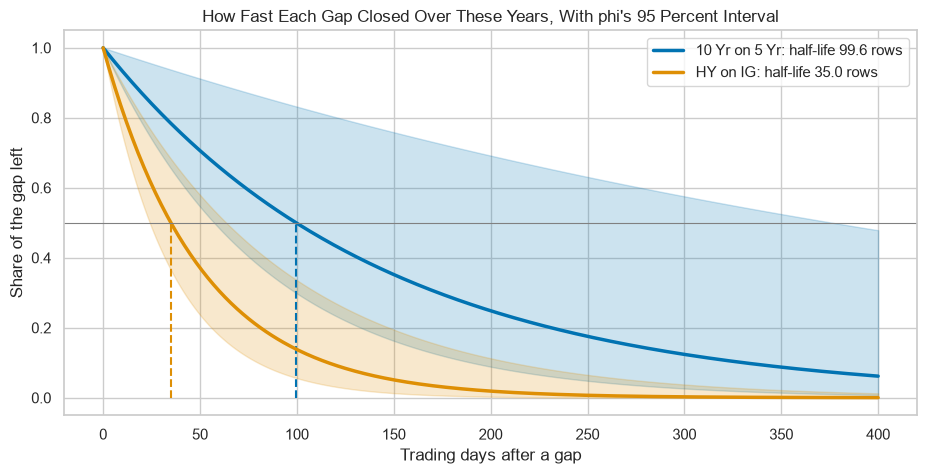

In [29]:
# the share of a gap left after each row, phi to the power of the rows, with the interval shaded and the half-life dropped to the axis
rows_after = np.arange(0, 401)
fig, ax = plt.subplots(figsize=(11, 5))
for (label, (low, phi, high)), colour in zip(intervals.items(), ["C0", "C1"]):
    half = np.log(0.5) / np.log(phi)
    ax.plot(rows_after, phi ** rows_after, color=colour, linewidth=2.5, label=f"{label}: half-life {half:.1f} rows")
    ax.fill_between(rows_after, low ** rows_after, high ** rows_after, color=colour, alpha=0.2)
    ax.vlines(half, 0, 0.5, color=colour, linestyle="--")
ax.axhline(0.5, color="gray", linewidth=0.8)
ax.set(xlabel="Trading days after a gap", ylabel="Share of the gap left", title="How Fast Each Gap Closed Over These Years, With phi's 95 Percent Interval")
ax.legend(loc="upper right")
plt.show()

HY on IG: 24.1 to 63.5 trading days around 35.0, the top end more than twice the bottom.

10 Yr on 5 Yr: 57.3 to 376.4, so wide that eight years pin down little.

**Predict 3**

A random walk has `phi` = 1, so in theory it has no half-life.

Q. Fit the same AR(1) to 1,000 random walks of 2,001 rows each. How many will give a `phi` below 1, and so a half-life? Write down a number.

## Half-Lives From Pure Random Walks

In [30]:
# 1,000 random walks as long as the development years, and each one's phi: Course 1's polyfit of a value on the value before
walks = rng.standard_normal((1000, 2001)).cumsum(axis=1)
walk_phis = np.array([np.polyfit(walk[:-1], walk[1:], 1)[0] for walk in walks])
walk_halves = np.log(0.5) / np.log(walk_phis[walk_phis < 1])
print((walk_phis < 1).sum(), "of 1,000 walks give a phi below 1")
print(f"their half-lives: median {np.median(walk_halves):.0f} rows, 10 to 90 percent {np.quantile(walk_halves, 0.1):.0f} to {np.quantile(walk_halves, 0.9):.0f}")
print("under 99.6 rows:", (walk_halves < 99.6).sum(), "| under 35.0 rows:", (walk_halves < 35.0).sum())

967 of 1,000 walks give a phi below 1
their half-lives: median 306 rows, 10 to 90 percent 124 to 998
under 99.6 rows: 54 | under 35.0 rows: 0


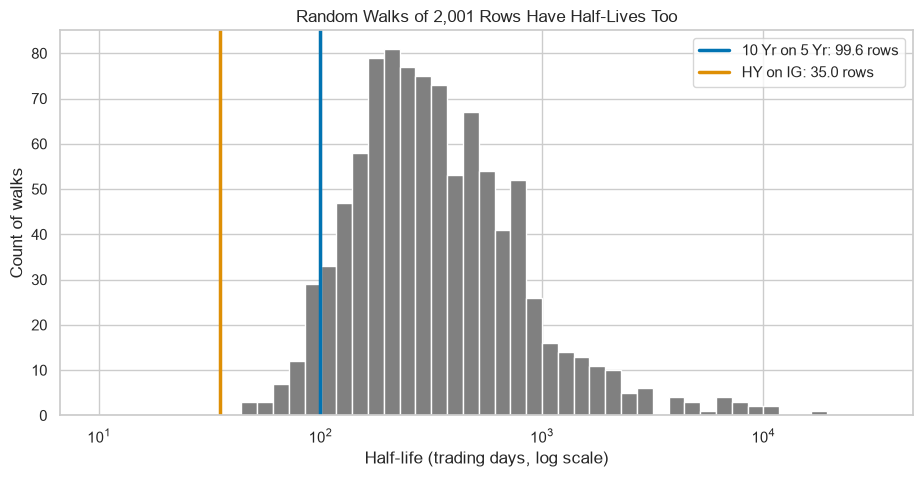

In [31]:
# the walks' half-lives on a log axis, with the two gaps' half-lives marked
fig, ax = plt.subplots(figsize=(11, 5))
ax.hist(walk_halves, bins=np.logspace(1, 4.5, 50), color="gray")
for (label, (low, phi, high)), colour in zip(intervals.items(), ["C0", "C1"]):
    ax.axvline(np.log(0.5) / np.log(phi), color=colour, linewidth=2.5, label=f"{label}: {np.log(0.5) / np.log(phi):.1f} rows")
ax.set(xscale="log", xlabel="Half-life (trading days, log scale)", ylabel="Count of walks", title="Random Walks of 2,001 Rows Have Half-Lives Too")
ax.legend(loc="upper right")
plt.show()

967 of 1,000 walks give a `phi` below 1, with half-lives from 124 to 998 rows for the middle 80 percent.

54 walks have a half-life under the Treasury gap's 99.6 rows; none comes under HY's 35.0.

On a sample of this length, least squares tends to put a walk's `phi` a little below 1, so a half-life alone cannot say a gap comes back.

**A half-life is a description, not a test: read it after `coint`, never instead.**

# The Hedge Ratio Through the Years

## A Rolling Ratio

Course 4's Day 11 rolling covariance over the rolling variance gives each date the hedge ratio of the 252 dates up to it.

In [32]:
# each date's hedge ratio from the 252 dates up to it, and each fold's ratio from its training levels
rolling_ratio, fold_ratio = {}, {}
for label, (y_name, x_name) in pairs.items():
    y, x = levels[y_name], levels[x_name]
    rolling_ratio[label] = y.rolling(252).cov(x) / x.rolling(252).var()
    fold_ratio[label] = [np.polyfit(x.iloc[train], y.iloc[train], 1)[0] for train, test in folds]
    low, high = rolling_ratio[label].idxmin(), rolling_ratio[label].idxmax()
    print(f"{label}: rolling from {rolling_ratio[label][low]:.2f} ({low.date()}) to {rolling_ratio[label][high]:.2f} ({high.date()}) | folds {np.round(fold_ratio[label], 3)}")

10 Yr on 5 Yr: rolling from 0.40 (2022-02-04) to 1.81 (2021-03-30) | folds [0.906 0.743 0.762 0.889 0.861]
HY on IG: rolling from 2.38 (2018-11-05) to 5.65 (2016-11-14) | folds [3.972 3.475 3.69  3.646 3.895]


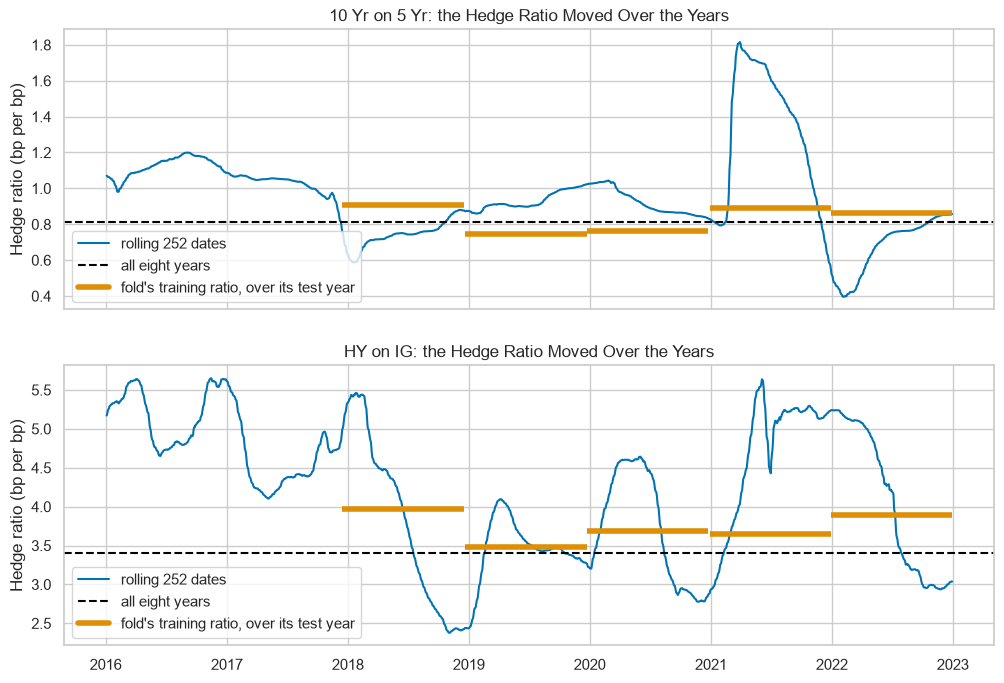

In [33]:
# the rolling ratio, the ratio of all eight years dashed, and each fold's training ratio over the year it is tested on
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for ax, label in zip(axes, pairs):
    ax.plot(rolling_ratio[label], color="C0", label="rolling 252 dates")
    ax.axhline(np.polyfit(levels[pairs[label][1]], levels[pairs[label][0]], 1)[0], color="black", linestyle="--", label="all eight years")
    for (train, test), ratio in zip(folds, fold_ratio[label]):
        ax.hlines(ratio, levels.index[test[0]], levels.index[test[-1]], color="C1", linewidth=4)
    ax.plot([], [], color="C1", linewidth=4, label="fold's training ratio, over its test year")
    ax.set(ylabel="Hedge ratio (bp per bp)", title=f"{label}: the Hedge Ratio Moved Over the Years")
    ax.legend(loc="lower left")
plt.show()

The 10 Yr on the 5 Yr: the rolling ratio ran from 0.40 to 1.81, and the folds' training ratios from 0.743 to 0.906.

HY on IG: from 2.38 to 5.65, with fold ratios from 3.475 to 3.972.

A trading year's ratio can sit far from the ratio of all eight years.

**Predict 4**

Q. Take fold 1's training line for the 10 Yr on the 5 Yr, and build the gap with it on the next 252 dates. What share of those dates will sit beyond 2 standard deviations of the training gap? Write down a percent.

## The Training Line on the Next Year's Dates

In [34]:
# for each fold: the line fitted on the training levels, then the gap on the 252 test dates with that same line
rows, test_gaps = [], {}
for label, (y_name, x_name) in pairs.items():
    y, x = levels[y_name], levels[x_name]
    for k, (train, test) in enumerate(folds, start=1):
        ratio, constant = np.polyfit(x.iloc[train], y.iloc[train], 1)
        train_std = (y.iloc[train] - constant - ratio * x.iloc[train]).std()
        test_gaps[label, k] = (y.iloc[test] - constant - ratio * x.iloc[test], train_std)
        rows.append({"pair": label, "fold": k, "dates beyond 2 std": (test_gaps[label, k][0].abs() > 2 * train_std).sum()})
pd.DataFrame(rows).pivot(index="pair", columns="fold", values="dates beyond 2 std")

fold,1,2,3,4,5
pair,,,,,
10 Yr on 5 Yr,227,116,196,44,26
HY on IG,8,0,3,32,69


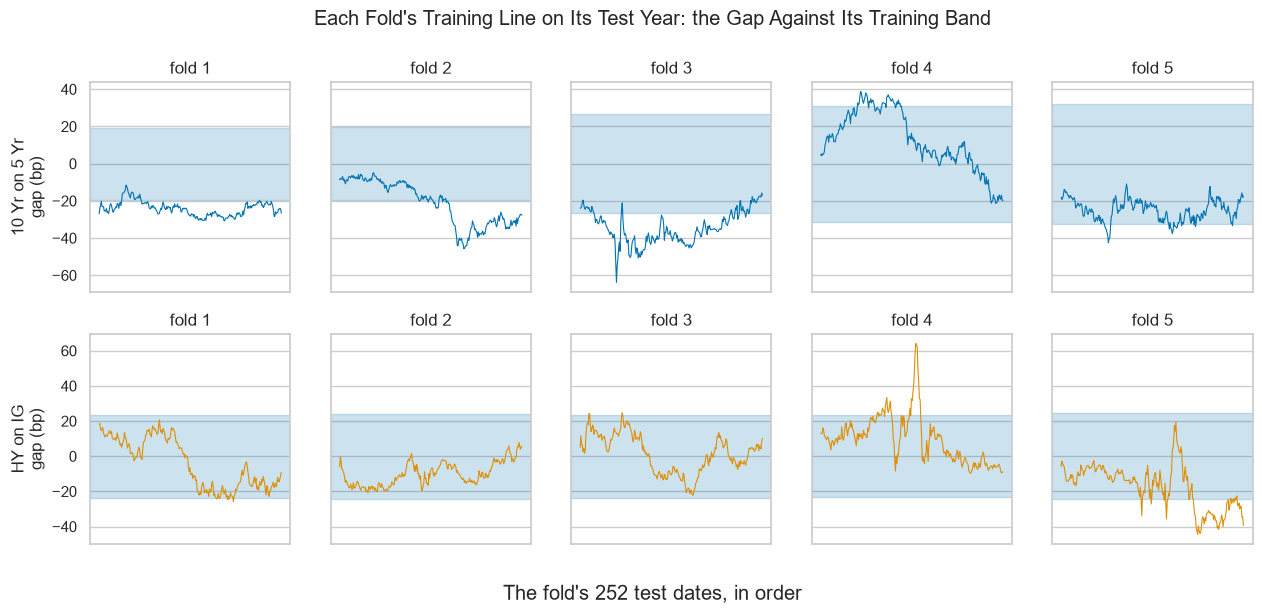

In [35]:
# each fold's test gap inside its training band of 2 standard deviations
fig, axes = plt.subplots(2, 5, figsize=(15, 6), sharey="row")
for row, label in enumerate(pairs):
    for k in range(1, 6):
        gap, train_std = test_gaps[label, k]
        ax = axes[row, k - 1]
        ax.axhspan(-2 * train_std, 2 * train_std, color="C0", alpha=0.2)
        ax.plot(gap.to_numpy(), color="C0" if row == 0 else "C1", linewidth=0.8)
        ax.set(title=f"fold {k}", xticks=[])
    axes[row, 0].set_ylabel(f"{label}\ngap (bp)")
fig.supxlabel("The fold's 252 test dates, in order")
fig.suptitle("Each Fold's Training Line on Its Test Year: the Gap Against Its Training Band", y=1.0)
plt.show()

10 Yr on 5 Yr, fold 1: 227 of 252 test dates, 90.1 percent, sit beyond the training band.

The line of 2015 to 2017 missed 2018 almost entirely.

The Treasury line left at least 26 dates outside in every fold, 10 percent or more.

HY on IG: 8, 0 and 3 dates outside in folds 1 to 3, then 32 and 69 in 2021 and 2022.

**A ratio describes the years it was fitted on. On later dates HY's line left 8 dates or fewer outside its band in three folds of five, the Treasury line at least 26 in every fold.**

# Insights and Conclusion

Correlation did not separate the two pairs; the gap did.

Least squares gives the tightest gap, so a fitted gap is read against Engle-Granger's table, not ADF's: 165 of 1,000 unrelated pairs pass Day 3's.

For HY on IG, Engle-Granger rejects no cointegration over these years (p 0.0032), with a half-life of 35 trading days (24 to 64), a tie Course 3's generator put there.

For the real pair, 10 Yr on 5 Yr, it does not (p 0.43), yet its gap has a half-life too, as 967 of 1,000 walks do.

The hedge ratio drifts, and a training line can miss its next year.

Every number here describes 2015 to 2022.

**Test the gap with `coint` first, then measure its half-life, then check its line on later dates.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Compare a pair's correlation in levels and in changes, and say why it cannot settle a link.
* Fit a hedge ratio by least squares and build the gap.
* Draw a vector field of a pair's moves from where it stood.
* Run Engle-Granger with `coint` and read its statistic and p-value.
* Measure a gap's half-life from an AR(1), with its interval, and check its sign.
* Follow a hedge ratio through the years and test a training line on later dates.

## Exercises

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [36]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**The Hedge Ratio on Changes, Fold 1**

Q. Fit the 10 Yr on the 5 Yr by least squares on the daily changes up to fold 1's last training date, `changes.loc[:"2017-12-14"]`, and store the hedge ratio in `ex1_ratio`.

In [37]:
# fold 1's training dates end on 2017-12-14: the daily changes up to that date
fold1_changes = changes.loc[:"2017-12-14"]

# the 10 Yr's change on the 5 Yr's, by least squares: the slope is the hedge ratio
fit = sm.OLS(fold1_changes["10 Yr"].to_numpy(), sm.add_constant(fold1_changes["5 Yr"].to_numpy())).fit()
ex1_ratio = fit.params[1]
print(f"hedge ratio on fold 1's changes: {ex1_ratio:.3f}")

hedge ratio on fold 1's changes: 0.973


In [38]:
check("Exercise 1 hedge ratio on changes", ex1_ratio, 0.972877171271533)

Exercise 1 hedge ratio on changes: correct


### Exercise 2

**A Function for Engle-Granger**

Q. Write `engle_granger_p(y, x, trend="c")` that returns the p-value of `coint` with `autolag="aic"`. Store its p-value for HY on IG with `trend="ct"`, a constant and a trend, in `ex2_p`.

In [39]:
# coint's p-value is the second of the three things it returns
def engle_granger_p(y, x, trend="c"):
    """Engle-Granger's p-value for y on x."""
    return coint(y.to_numpy(), x.to_numpy(), trend=trend, autolag="aic")[1]

ex2_p = engle_granger_p(levels["HY"], levels["IG"], trend="ct")
print(f"with a constant: {engle_granger_p(levels['HY'], levels['IG']):.4f} | with a constant and a trend: {ex2_p:.4f}")

with a constant: 0.0032 | with a constant and a trend: 0.0121


In [40]:
check("Exercise 2 p-value with a trend", ex2_p, 0.012146557616341985)

Exercise 2 p-value with a trend: correct


### Exercise 3

**Engle-Granger on Each Fold's Training Years**

Q. Run `coint` for HY on IG on each fold's training levels. In how many of the five folds is the p-value below 0.05? Store the count in `ex3_count`.

In [41]:
# Engle-Granger's p-value on each fold's training levels only
fold_p = [engle_granger_p(levels["HY"].iloc[train], levels["IG"].iloc[train]) for train, test in folds]
ex3_count = sum(p < 0.05 for p in fold_p)
print("p-values:", np.round(fold_p, 4), "| below 0.05:", ex3_count)

p-values: [0.3248 0.0693 0.0787 0.0304 0.0014] | below 0.05: 2


In [42]:
check("Exercise 3 folds below 0.05", ex3_count, 2)

Exercise 3 folds below 0.05: correct


### Exercise 4

**The Other Way Round**

Q. Run `coint` with IG as y and HY as x, and store the p-value in `ex4_p`.

In [43]:
# the same test with the two series swapped
ex4_p = engle_granger_p(levels["IG"], levels["HY"])
print(f"IG on HY: {ex4_p:.4f}")

IG on HY: 0.0126


In [44]:
check("Exercise 4 IG on HY p-value", ex4_p, 0.012554489157097214)

Exercise 4 IG on HY p-value: correct


Optional, with Course 3's FRED key: run the same steps on two ICE BofA spread series on your own screen.
Licensed series are never saved or shared (Course 3).

### Exercise 5: AI check

**A Half-Life With the Wrong Sign**

You asked an AI assistant for a function that gives a gap's half-life.
This came back.
It runs, and it returns a number.
Test it, then find the one bug.

In [45]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def half_life_rows(gap):
    """Rows for half of a gap to close: regress the change on the gap the row before."""
    slope = np.polyfit(gap[:-1], np.diff(gap), 1)[0]
    return np.log(2) / slope

# a made-up gap of 800 rows with phi 0.9, from a generator of its own
test_rng = np.random.default_rng(SEED)
test_gap = np.zeros(800)
for row in range(1, 800):
    test_gap[row] = 0.9 * test_gap[row - 1] + test_rng.standard_normal()
print("half-life:", round(half_life_rows(test_gap), 2), "rows")

half-life: -6.01 rows


In [46]:
# the test, from the docstring: phi 0.9 closes half a gap in about 6.6 rows, so the answer must be positive and near it
assert abs(half_life_rows(test_gap) - 6.58) < 2, "a negative half-life: the slope of a closing gap is below zero"

AssertionError: a negative half-life: the slope of a closing gap is below zero

Q. Fix the function, and store its answer for `test_gap` in `ex5_half_life`.

In [47]:
# the change regressed on the gap before has a slope below zero for a closing gap, so the half-life divides by minus it
# (ln 2 / -slope is the short form of ln 0.5 / ln(1 + slope), close when the slope is near 0)
def half_life_rows(gap):
    """Rows for half of a gap to close: regress the change on the gap the row before."""
    slope = np.polyfit(gap[:-1], np.diff(gap), 1)[0]
    return np.log(2) / -slope

ex5_half_life = half_life_rows(test_gap)
print("half-life:", round(ex5_half_life, 2), "rows")

half-life: 6.01 rows


In [48]:
check("Exercise 5 the half-life", ex5_half_life, 6.009051438388675)

Exercise 5 the half-life: correct


## Congratulations!

You took two pairs that a correlation could not tell apart and told them apart.
You found a hedge ratio by eye and by least squares, mapped where each pair went from where it stood, and tested the gap against the table it belongs to.
You measured how fast a gap closed, with its interval, and saw that a random walk gives a half-life too, so the test comes first.
In the capstone you bring the course's models together and open the held-out years once.

[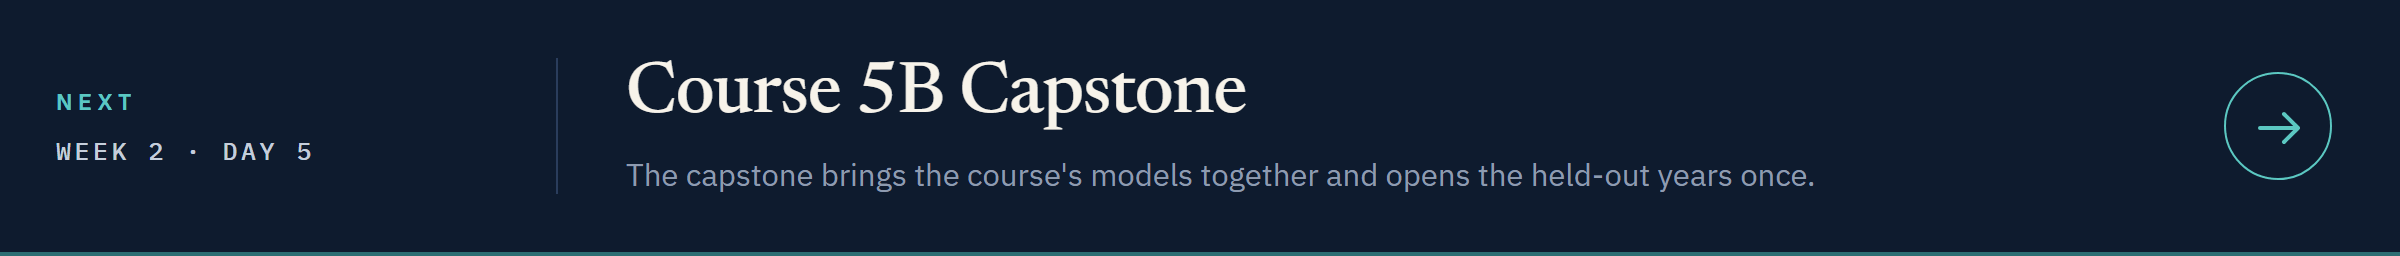](../day5/course5b_capstone.ipynb)

[Open Day 5 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05b_time_series/week2/day5/course5b_capstone.ipynb)